# EN3150 Assignment 03: Model B vs lightweight SOTA models (Task 6)

Compares the custom resource-constrained CNN (**Model B**, depthwise separable, 25,526 parameters) with the two
fine-tuned lightweight pretrained networks (**MobileNetV2** and **EfficientNet-B0**) on the three axes the task asks
for: **accuracy**, **memory footprint** and **computational cost**. Model A is included as a reference point.

Nothing is trained here: accuracy, size and timing come from the files saved by each model's notebook in
`results/<Model>/`. All four models used the same splits, the same augmentation and the same GPU (GTX 1660 Ti).

| Model | Notebook | Training |
|---|---|---|
| Model A | `Model_A/src/ModelA.ipynb` | from scratch, 25 epochs |
| Model B | `Model_B/src/ModelB.ipynb` | from scratch, 25 epochs |
| MobileNetV2 | `SOTA/MobileNetV2/src/MobileNetV2_Retrain.ipynb` | ImageNet-pretrained, 3 + 17 epochs |
| EfficientNet-B0 | `SOTA/EfficientNetB0/src/EfficientNetB0_Retrain.ipynb` | ImageNet-pretrained, 3 + 17 epochs |

Outputs: `results/Comparisons/final_comparison.csv` and the `final_*.png` figures in the same folder.

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torchvision.models import mobilenet_v2, efficientnet_b0


# Walk up from the notebook's folder to the repository root (the folder that contains .git)
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Common.models import ModelA, ModelB
from Common.complexity import count_macs

RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR = RESULTS_DIR / "Comparisons"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Same folder / file prefix / architecture as each model's notebook (weights are not needed here)
MODELS = {
    "Model A": ("Model_A", "model_a", lambda: ModelA()),
    "Model B": ("Model_B", "model_b", lambda: ModelB()),
    "MobileNetV2": ("MobileNetV2", "mobilenetv2", lambda: mobilenet_v2(num_classes=43)),
    "EfficientNet-B0": ("EfficientNetB0", "efficientnetb0", lambda: efficientnet_b0(num_classes=43)),
}

# One fixed colour and marker per model in every figure (validated categorical palette)
COLORS = {"Model A": "#2a78d6", "Model B": "#eb6834", "MobileNetV2": "#1baf7a", "EfficientNet-B0": "#eda100"}
MARKERS = {"Model A": "o", "Model B": "s", "MobileNetV2": "^", "EfficientNet-B0": "D"}
# MobileNetV2 and EfficientNet-B0 sit almost on top of each other, so their labels go on opposite sides
LABEL_OFFSETS = {
    "Model A": ((9, -4), "left", "top"),
    "Model B": ((9, -4), "left", "top"),
    "MobileNetV2": ((-9, 6), "right", "bottom"),
    "EfficientNet-B0": ((9, -6), "left", "top"),
}

# Neutral chart styling: light surface, recessive grid and axes
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#898781",
    "ytick.color": "#898781",
    "text.color": "#0b0b0b",
    "font.size": 10,
})

## 1. Load every model's results

Model sizes are converted to MB (the SOTA notebooks already save MB; Models A and B save KB). MACs are counted from
each architecture with `Common/complexity.py`. Training time per epoch is the **median** over all epochs, as in the
Model A vs Model B comparison; for the SOTA models this is a full fine-tuning epoch (the 3 head-only epochs, with the
backbone frozen, are faster and are reported separately).

In [2]:
# Collect one row of measurements per model
rows = {}
histories = {}
reports = {}

for name, (folder, prefix, build) in MODELS.items():
    model_dir = RESULTS_DIR / folder
    metrics = pd.read_csv(model_dir / f"{prefix}_metrics.csv").iloc[0]

    with (model_dir / f"{prefix}_history.json").open(encoding="utf-8") as history_file:
        history = json.load(history_file)
    with (model_dir / f"{prefix}_classification_report.json").open(encoding="utf-8") as report_file:
        reports[name] = json.load(report_file)
    histories[name] = history

    # The SOTA notebooks save size in MB, Models A and B in KB
    if "Model Size (MB)" in metrics:
        size_mb = metrics["Model Size (MB)"]
    else:
        size_mb = metrics["Actual Model Size (KB)"] / 1024

    model = build()
    # The rebuilt architecture must have the trained model's parameter count
    assert sum(p.numel() for p in model.parameters()) == metrics["Parameters"], name

    epoch_times = np.array(history["epoch_time"])
    rows[name] = {
        "Parameters": int(metrics["Parameters"]),
        "Model Size on Disk (MB)": size_mb,
        "Estimated INT8 Size (MB)": metrics["Parameters"] / 1024 ** 2,
        "MACs per Image (M)": count_macs(model) / 1e6,
        "Epochs Trained": len(epoch_times),
        "Training Time per Epoch (s)": float(np.median(epoch_times)),
        "GPU Inference (ms/image)": metrics["Inference Time (ms/image)"],
        "Test Accuracy (%)": metrics["Test Accuracy"] * 100,
        "Macro Precision (%)": metrics["Macro Precision"] * 100,
        "Macro Recall (%)": metrics["Macro Recall"] * 100,
    }

    # SOTA head-only epochs (frozen backbone) are faster, so they are reported separately
    if "stage" in history:
        head = [t for t, stage in zip(epoch_times, history["stage"]) if stage == "head"]
        print(f"{name}: head-only epochs (frozen backbone) median {np.median(head):.1f} s")

MobileNetV2: head-only epochs (frozen backbone) median 40.6 s
EfficientNet-B0: head-only epochs (frozen backbone) median 48.4 s


## 2. CPU latency for one image

GPU timings hide the benefit of fewer MACs: a GPU finishes these small models almost instantly and is limited by
per-layer overhead and data movement. Edge devices are CPU-bound, so each architecture is also timed on the CPU with
**one thread** and **batch size 1** (one $64 \times 64$ image at a time), which is closer to a Raspberry Pi or
microcontroller-class processor. Latency does not depend on the trained weight values, so randomly initialised copies
of the architectures are timed. The median of 200 runs is reported after 20 warm-up runs. Absolute values depend on
this CPU; the ratios between models are what matter.

In [3]:
default_threads = torch.get_num_threads()
# Single thread, batch size 1: closer to a small edge CPU
torch.set_num_threads(1)

image = torch.randn(1, 3, 64, 64)

for name, (_, _, build) in MODELS.items():
    model = build().eval()
    timings = []

    with torch.inference_mode():
        # 20 warm-up runs, then 200 timed runs (median reported)
        for _ in range(20):
            model(image)
        for _ in range(200):
            start = time.perf_counter()
            model(image)
            timings.append((time.perf_counter() - start) * 1000)

    rows[name]["CPU Latency, 1 thread (ms/image)"] = float(np.median(timings))

torch.set_num_threads(default_threads)
print("CPU:", platform.processor() or platform.machine())

CPU: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel


## 3. Comparison table

In [4]:
# Task 6 table: accuracy, memory footprint and computational cost
comparison = pd.DataFrame(rows).T
comparison.index.name = "Model"
comparison = comparison[[
    "Test Accuracy (%)",
    "Macro Precision (%)",
    "Macro Recall (%)",
    "Parameters",
    "Model Size on Disk (MB)",
    "Estimated INT8 Size (MB)",
    "MACs per Image (M)",
    "CPU Latency, 1 thread (ms/image)",
    "GPU Inference (ms/image)",
    "Training Time per Epoch (s)",
    "Epochs Trained"
]]

comparison.to_csv(OUTPUT_DIR / "final_comparison.csv")

comparison.astype({"Parameters": int, "Epochs Trained": int}).round(3)

,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Parameters,Model Size on Disk (MB),Estimated INT8 Size (MB),MACs per Image (M),"CPU Latency, 1 thread (ms/image)",GPU Inference (ms/image),Training Time per Epoch (s),Epochs Trained
Model,,,,,,,,,,,
Model A,98.974,98.738,99.165,45643,0.179,0.044,9.459,1.517,0.358,40.985,25
Model B,96.997,97.488,97.359,25526,0.103,0.024,1.421,1.609,0.340,44.198,25
MobileNetV2,100.000,100.000,100.000,2278955,8.930,2.173,24.504,6.944,0.598,55.847,20
EfficientNet-B0,99.825,99.873,99.912,4062631,15.787,3.874,32.022,10.353,0.671,70.087,20


### 3.1 Cost of each SOTA model relative to Model B

How many times larger or more expensive each pretrained model is than Model B, and how much accuracy that buys.

In [5]:
# How many times larger / slower each SOTA model is than Model B, and its accuracy gain
base = comparison.loc["Model B"]
ratio_columns = [
    "Parameters",
    "Model Size on Disk (MB)",
    "MACs per Image (M)",
    "CPU Latency, 1 thread (ms/image)",
    "GPU Inference (ms/image)",
    "Training Time per Epoch (s)"
]

relative = pd.DataFrame({
    name: {column: f"{comparison.loc[name, column] / base[column]:.1f}x" for column in ratio_columns}
    | {"Test Accuracy": f"{comparison.loc[name, 'Test Accuracy (%)'] - base['Test Accuracy (%)']:+.2f} pts"}
    for name in ["MobileNetV2", "EfficientNet-B0"]
})
relative.columns = [f"{name} vs Model B" for name in relative.columns]

relative

,MobileNetV2 vs Model B,EfficientNet-B0 vs Model B
Parameters,89.3x,159.2x
Model Size on Disk (MB),86.5x,152.9x
MACs per Image (M),17.2x,22.5x
"CPU Latency, 1 thread (ms/image)",4.3x,6.4x
GPU Inference (ms/image),1.8x,2.0x
Training Time per Epoch (s),1.3x,1.6x
Test Accuracy,+3.00 pts,+2.83 pts


## 4. Trade-off plots

Each point is one model; up and to the left is better (more accurate, smaller or cheaper). The x-axes are
logarithmic because the models differ by up to two orders of magnitude.

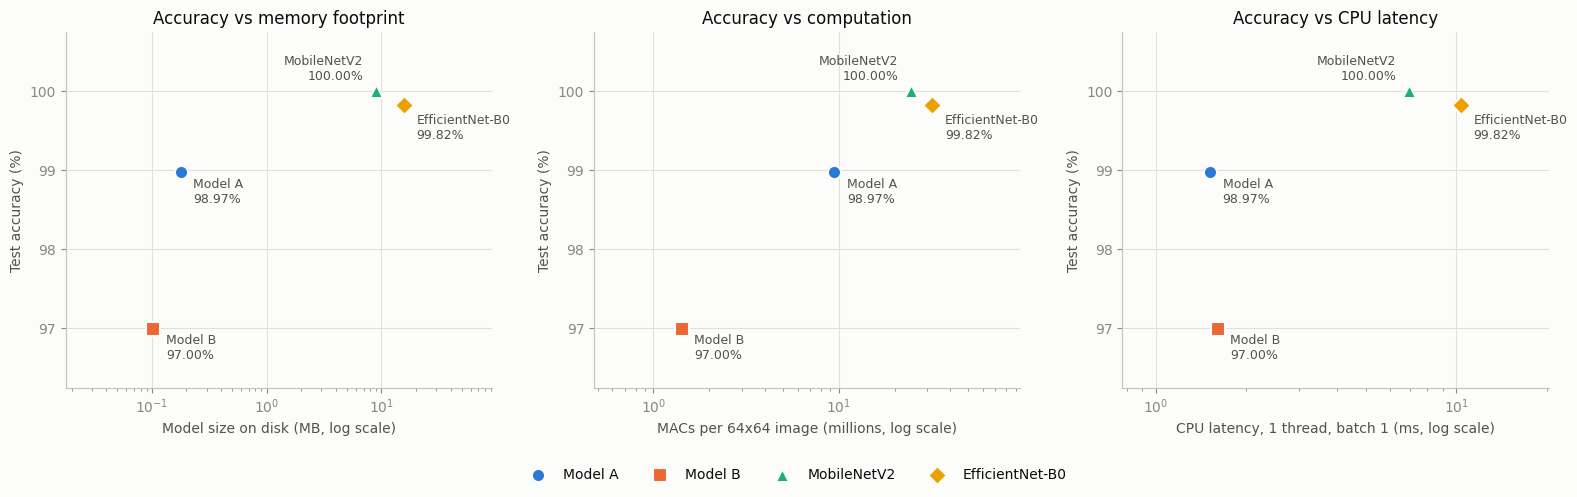

In [6]:
# One marker per model with a direct label, so colour is never the only cue
def label_points(ax, x_column):
    for name in comparison.index:
        x, y = comparison.loc[name, x_column], comparison.loc[name, "Test Accuracy (%)"]
        ax.scatter(x, y, s=90, color=COLORS[name], marker=MARKERS[name], edgecolor="#fcfcfb", linewidth=1.5,
                   zorder=3, label=name)
        offset, ha, va = LABEL_OFFSETS[name]
        ax.annotate(f"{name}\n{y:.2f}%", (x, y), textcoords="offset points", xytext=offset,
                    fontsize=9, color="#52514e", ha=ha, va=va)


# Accuracy against memory, MACs and CPU latency (log x-axes)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, column, xlabel in [
    (axes[0], "Model Size on Disk (MB)", "Model size on disk (MB, log scale)"),
    (axes[1], "MACs per Image (M)", "MACs per 64x64 image (millions, log scale)"),
    (axes[2], "CPU Latency, 1 thread (ms/image)", "CPU latency, 1 thread, batch 1 (ms, log scale)")
]:
    label_points(ax, column)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Test accuracy (%)")
    ax.margins(x=0.35, y=0.25)

axes[0].set_title("Accuracy vs memory footprint")
axes[1].set_title("Accuracy vs computation")
axes[2].set_title("Accuracy vs CPU latency")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(OUTPUT_DIR / "final_tradeoffs.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Training behaviour

Validation accuracy per epoch. The pretrained models start from ImageNet features: once the whole network is unfrozen
(after epoch 3, dashed line) they pass 99% within a few epochs, while the from-scratch models need many more epochs.

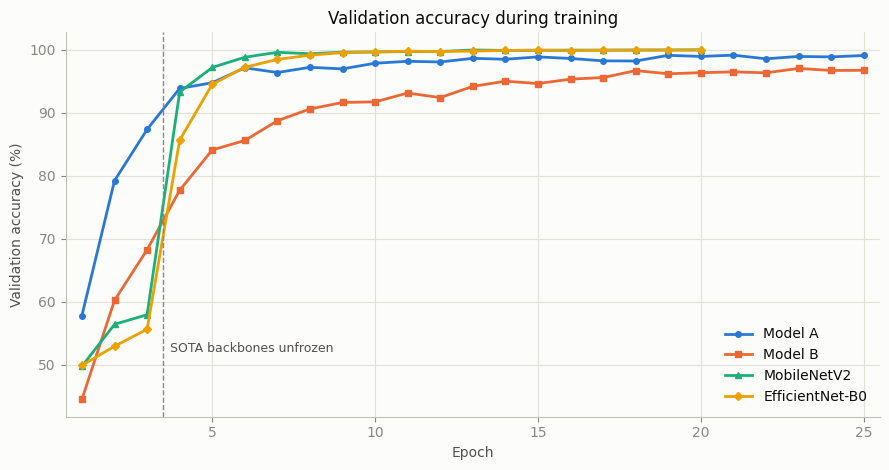

Model A: first epoch with validation accuracy >= 99%: 19
Model B: first epoch with validation accuracy >= 99%: None
MobileNetV2: first epoch with validation accuracy >= 99%: 7
EfficientNet-B0: first epoch with validation accuracy >= 99%: 8


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for name, history in histories.items():
    epochs = np.arange(1, len(history["val_accuracy"]) + 1)
    ax.plot(epochs, np.array(history["val_accuracy"]) * 100, color=COLORS[name], linewidth=2,
            marker=MARKERS[name], markersize=4, label=name)

# Dashed line: where the SOTA backbones are unfrozen
ax.axvline(3.5, color="#898781", linestyle="--", linewidth=1)
ax.text(3.7, 52, "SOTA backbones unfrozen", fontsize=9, color="#52514e")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Validation accuracy during training")
ax.set_xlim(0.5, 25.5)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_validation_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

for name, history in histories.items():
    first_99 = next((i + 1 for i, acc in enumerate(history["val_accuracy"]) if acc >= 0.99), None)
    print(f"{name}: first epoch with validation accuracy >= 99%: {first_99}")

## 6. Where the pretrained models do better

Recall on the eight classes where Model B is weakest. These are mostly speed-limit signs, which differ only in their
digits.

In [8]:
# Recall per class for every model; show Model B's eight weakest classes
class_recall = pd.DataFrame({
    name: {int(k): v["recall"] * 100 for k, v in report.items() if k.isdigit()}
    for name, report in reports.items()
})
class_recall.index.name = "Class"
class_recall.insert(0, "Support", [int(reports["Model B"][str(k)]["support"]) for k in class_recall.index])

class_recall.sort_values("Model B").head(8).round(2)

,Support,Model A,Model B,MobileNetV2,EfficientNet-B0
Class,,,,,
41,35,94.29,82.86,100.0,100.00
2,233,99.14,88.84,100.0,98.71
5,209,98.56,89.95,100.0,99.52
3,148,97.97,92.57,100.0,100.00
23,44,100.00,93.18,100.0,100.00
7,155,98.06,94.19,100.0,100.00
0,19,100.00,94.74,100.0,100.00
29,21,100.00,95.24,100.0,100.00
